In [ ]:
!pip install -q gradio scikit-learn pandas matplotlib seaborn


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving jd_analyzer_dataset.csv to jd_analyzer_dataset (2).csv


In [ ]:
df = pd.read_csv("jd_analyzer_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (600, 3)


,job_description,job_category,required_skills
0,Looking for a Full Stack Developer to build re...,Web Development,"REST API, JavaScript, HTML, MongoDB, CSS, Reac..."
1,Information Security Analyst required to respo...,Cyber Security,"Linux, Python, Cryptography, Network Security,..."
2,SQL Developer required to perform backups. Can...,Database Administration,"SQL, PostgreSQL, Performance Tuning, Database ..."
3,Looking for a Data Scientist to build predicti...,Data Science,"Data Visualization, NumPy, Python, Pandas, Sta..."
4,We are hiring a Web Development Intern who can...,Web Development,"MongoDB, HTML, Git, REST API, CSS, React, Java..."


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows: 600
Number of columns: 3

Column names:
['job_description', 'job_category', 'required_skills']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   job_description  600 non-null    object
 1   job_category     600 non-null    object
 2   required_skills  600 non-null    object
dtypes: object(3)
memory usage: 14.2+ KB


In [ ]:
print("Job Categories:\n")

for category in df["job_category"].unique():
    print("-", category)

Job Categories:

- Web Development
- Cyber Security
- Database Administration
- Data Science
- Machine Learning
- Cloud Computing


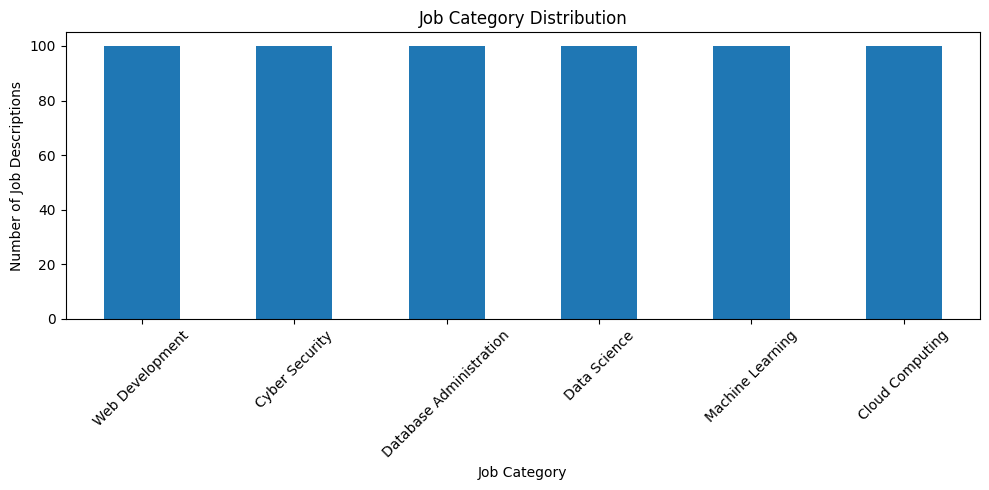

In [ ]:
plt.figure(figsize=(10, 5))

df["job_category"].value_counts().plot(kind="bar")

plt.title("Job Category Distribution")
plt.xlabel("Job Category")
plt.ylabel("Number of Job Descriptions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
def clean_text(text):
    text = text.lower()

    # Remove special characters
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text)

    return text.strip()


df["clean_description"] = df["job_description"].apply(clean_text)

df[["job_description", "clean_description"]].head()

,job_description,clean_description
0,Looking for a Full Stack Developer to build re...,looking for a full stack developer to build re...
1,Information Security Analyst required to respo...,information security analyst required to respo...
2,SQL Developer required to perform backups. Can...,sql developer required to perform backups cand...
3,Looking for a Data Scientist to build predicti...,looking for a data scientist to build predicti...
4,We are hiring a Web Development Intern who can...,we are hiring a web development intern who can...


In [ ]:
X = df["clean_description"]
y = df["job_category"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
0    looking for a full stack developer to build re...
1    information security analyst required to respo...
2    sql developer required to perform backups cand...
3    looking for a data scientist to build predicti...
4    we are hiring a web development intern who can...
Name: clean_description, dtype: object

Target:
0            Web Development
1             Cyber Security
2    Database Administration
3               Data Science
4            Web Development
Name: job_category, dtype: object


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 480
Testing samples: 120


In [ ]:
tfidf = TfidfVectorizer(
    max_features=3000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training matrix shape: (480, 1002)
Testing matrix shape: (120, 1002)


In [ ]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
import pickle
import os

os.makedirs("model", exist_ok=True)

# Save trained ML model
with open("model/model.pkl", "wb") as f:
    pickle.dump(model, f)

# Save TF-IDF vectorizer
with open("model/vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)

print("Model files created successfully!")

Model files created successfully!


In [ ]:
import os

print(os.listdir("model"))
files.download("model/model.pkl")
files.download("model/vectorizer.pkl")

['vectorizer.pkl', 'model.pkl']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
y_pred = model.predict(X_test_tfidf)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
for actual, predicted in zip(y_test.iloc[:10], y_pred[:10]):
    print("Actual:", actual, "| Predicted:", predicted)

Predictions generated successfully!

First 10 predictions:
Actual: Data Science | Predicted: Data Science
Actual: Cloud Computing | Predicted: Cloud Computing
Actual: Database Administration | Predicted: Database Administration
Actual: Machine Learning | Predicted: Machine Learning
Actual: Database Administration | Predicted: Database Administration
Actual: Machine Learning | Predicted: Machine Learning
Actual: Data Science | Predicted: Data Science
Actual: Web Development | Predicted: Web Development
Actual: Machine Learning | Predicted: Machine Learning
Actual: Machine Learning | Predicted: Machine Learning


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy: {:.2f}%".format(accuracy * 100))


Model Accuracy: 100.00%


In [ ]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Classification Report:

                         precision    recall  f1-score   support

        Cloud Computing       1.00      1.00      1.00        20
         Cyber Security       1.00      1.00      1.00        20
           Data Science       1.00      1.00      1.00        20
Database Administration       1.00      1.00      1.00        20
       Machine Learning       1.00      1.00      1.00        20
        Web Development       1.00      1.00      1.00        20

               accuracy                           1.00       120
              macro avg       1.00      1.00      1.00       120
           weighted avg       1.00      1.00      1.00       120



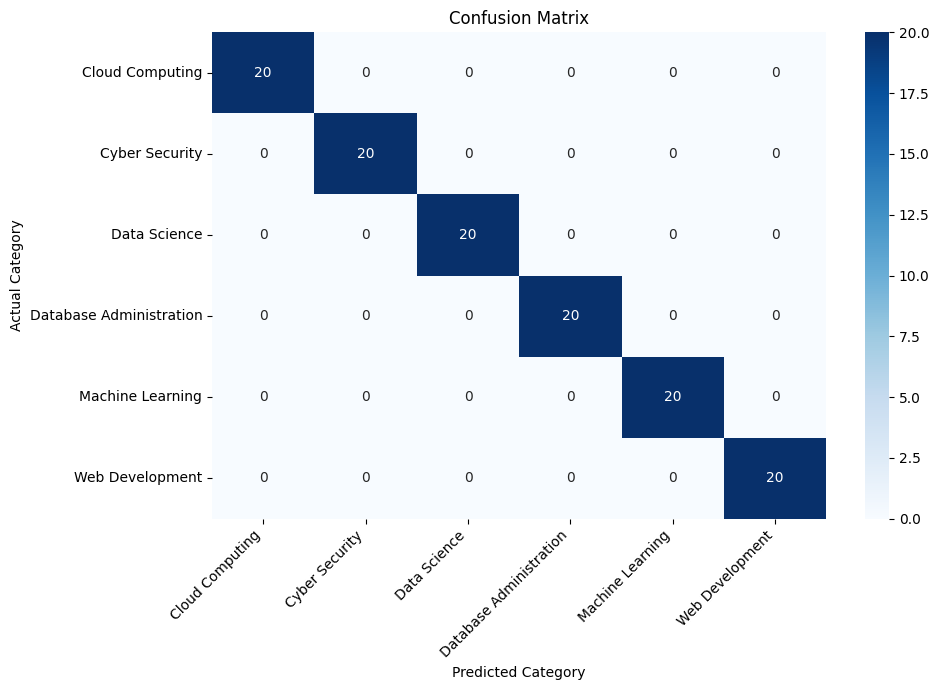

In [ ]:
cm = confusion_matrix(y_test, y_pred)

categories = sorted(df["job_category"].unique())

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=categories,
    yticklabels=categories
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
sample_jd = """
We are looking for a Data Scientist with experience in Python,
Pandas, NumPy, SQL and Machine Learning.
The candidate should also understand statistics and data visualization.
"""

# Clean the job description
cleaned_text = clean_text(sample_jd)

# Convert text into TF-IDF features
sample_vector = tfidf.transform([cleaned_text])

# Predict job category
prediction = model.predict(sample_vector)[0]

# Get prediction confidence
probability = model.predict_proba(sample_vector).max()

print("Job Description:")
print(sample_jd)

print("\nPredicted Job Category:")
print(prediction)

print("\nPrediction Confidence:")
print("{:.2f}%".format(probability * 100))

Job Description:

We are looking for a Data Scientist with experience in Python,
Pandas, NumPy, SQL and Machine Learning.
The candidate should also understand statistics and data visualization.


Predicted Job Category:
Data Science

Prediction Confidence:
83.44%


In [ ]:
# Create a dictionary from the dataset
category_skills = {}

for category in df["job_category"].unique():

    # Get all rows belonging to this category
    category_rows = df[df["job_category"] == category]

    # Collect all skills from required_skills column
    skills = set()

    for skill_text in category_rows["required_skills"]:

        skill_list = skill_text.split(",")

        for skill in skill_list:
            skills.add(skill.strip())

    category_skills[category] = sorted(skills)


# Display the skills learned from the dataset
for category, skills in category_skills.items():

    print("\n", category)
    print(skills)


 Web Development
['CSS', 'Git', 'HTML', 'JavaScript', 'MongoDB', 'Node.js', 'REST API', 'React']

 Cyber Security
['Cryptography', 'Ethical Hacking', 'Firewalls', 'Linux', 'Network Security', 'Python', 'SIEM', 'Vulnerability Assessment']

 Database Administration
['Backup and Recovery', 'Database Design', 'Linux', 'MySQL', 'Oracle', 'Performance Tuning', 'PostgreSQL', 'SQL']

 Data Science
['Data Visualization', 'Machine Learning', 'NumPy', 'Pandas', 'Python', 'SQL', 'Scikit-learn', 'Statistics']

 Machine Learning
['Deep Learning', 'Machine Learning', 'NumPy', 'Pandas', 'Python', 'Scikit-learn', 'Statistics', 'TensorFlow']

 Cloud Computing
['AWS', 'Azure', 'CI/CD', 'Docker', 'Git', 'Kubernetes', 'Linux', 'Networking']


In [ ]:
def skill_gap_detector(predicted_category, candidate_skills):

    # Get required skills from dataset
    required_skills = category_skills[predicted_category]

    # Convert candidate input into a list
    candidate_skill_list = [
        skill.strip().lower()
        for skill in candidate_skills.split(",")
    ]

    # Required skills in lowercase
    required_lower = {
        skill.lower(): skill
        for skill in required_skills
    }

    # Find matching skills
    matched_skills = []

    for skill in candidate_skill_list:

        if skill in required_lower:
            matched_skills.append(required_lower[skill])

    # Find missing skills
    missing_skills = []

    for skill in required_skills:

        if skill.lower() not in candidate_skill_list:
            missing_skills.append(skill)

    # Calculate percentage
    if len(required_skills) > 0:

        match_percentage = (
            len(matched_skills) /
            len(required_skills)
        ) * 100

    else:

        match_percentage = 0

    return (
        required_skills,
        matched_skills,
        missing_skills,
        match_percentage
    )

In [ ]:
predicted_category = "Data Science"

candidate_skills = "Python, SQL, HTML, CSS"

required, matched, missing, percentage = skill_gap_detector(
    predicted_category,
    candidate_skills
)

print("Predicted Job Category:")
print(predicted_category)

print("\nRequired Skills:")
print(", ".join(required))

print("\nCandidate Skills:")
print(candidate_skills)

print("\nMatched Skills:")
for skill in matched:
    print("✓", skill)

print("\nMissing Skills:")
for skill in missing:
    print("✗", skill)

print("\nSkill Match Percentage:")
print("{:.2f}%".format(percentage))

Predicted Job Category:
Data Science

Required Skills:
Data Visualization, Machine Learning, NumPy, Pandas, Python, SQL, Scikit-learn, Statistics

Candidate Skills:
Python, SQL, HTML, CSS

Matched Skills:
✓ Python
✓ SQL

Missing Skills:
✗ Data Visualization
✗ Machine Learning
✗ NumPy
✗ Pandas
✗ Scikit-learn
✗ Statistics

Skill Match Percentage:
25.00%


In [ ]:
def complete_analyzer(job_description, candidate_skills):

    # -----------------------------------
    # STEP 1: Clean job description
    # -----------------------------------

    cleaned_text = clean_text(job_description)


    # -----------------------------------
    # STEP 2: Convert text to TF-IDF
    # -----------------------------------

    job_vector = tfidf.transform([cleaned_text])


    # -----------------------------------
    # STEP 3: Predict job category
    # -----------------------------------

    predicted_category = model.predict(job_vector)[0]


    # -----------------------------------
    # STEP 4: Prediction confidence
    # -----------------------------------

    confidence = model.predict_proba(job_vector).max()


    # -----------------------------------
    # STEP 5: Get required skills
    # from the DATASET
    # -----------------------------------

    required_skills = category_skills[predicted_category]


    # -----------------------------------
    # STEP 6: Process candidate skills
    # -----------------------------------

    candidate_list = [
        skill.strip().lower()
        for skill in candidate_skills.split(",")
    ]


    # -----------------------------------
    # STEP 7: Find matched skills
    # -----------------------------------

    matched_skills = []

    for skill in required_skills:

        if skill.lower() in candidate_list:

            matched_skills.append(skill)


    # -----------------------------------
    # STEP 8: Find missing skills
    # -----------------------------------

    missing_skills = []

    for skill in required_skills:

        if skill.lower() not in candidate_list:

            missing_skills.append(skill)


    # -----------------------------------
    # STEP 9: Calculate skill match
    # -----------------------------------

    if len(required_skills) > 0:

        match_percentage = (
            len(matched_skills) /
            len(required_skills)
        ) * 100

    else:

        match_percentage = 0


    # -----------------------------------
    # STEP 10: Return results
    # -----------------------------------

    return {
        "category": predicted_category,
        "confidence": confidence * 100,
        "required_skills": required_skills,
        "matched_skills": matched_skills,
        "missing_skills": missing_skills,
        "match_percentage": match_percentage
    }

In [ ]:
import gradio as gr


def gradio_analyzer(job_description, candidate_skills):

    if not job_description.strip():

        return (
            "Please enter a job description.",
            "",
            "",
            "",
            ""
        )


    if not candidate_skills.strip():

        return (
            "Please enter your skills.",
            "",
            "",
            "",
            ""
        )


    result = complete_analyzer(
        job_description,
        candidate_skills
    )


    category = result["category"]

    confidence = "{:.2f}%".format(
        result["confidence"]
    )


    matched = "\n".join(
        ["✓ " + skill
         for skill in result["matched_skills"]]
    )


    missing = "\n".join(
        ["✗ " + skill
         for skill in result["missing_skills"]]
    )


    match = "{:.2f}%".format(
        result["match_percentage"]
    )


    return (
        category,
        confidence,
        matched,
        missing,
        match
    )

In [ ]:
with gr.Blocks(
    title="JD Analyzer & Skill Gap Detector"
) as demo:

    gr.Markdown(
        """
        # 📄 JD Analyzer & Skill Gap Detector

        ### Machine Learning Mini Project

        Analyze a job description and identify
        the candidate's skill gaps.
        """
    )


    with gr.Row():

        with gr.Column():

            job_input = gr.Textbox(
                label="Job Description",
                placeholder="Paste the job description here...",
                lines=10
            )


            skills_input = gr.Textbox(
                label="Your Skills",
                placeholder="Example: Python, SQL, HTML, CSS",
                lines=4
            )


            analyze_button = gr.Button(
                "🔍 Analyze"
            )


        with gr.Column():

            category_output = gr.Textbox(
                label="Predicted Job Category"
            )


            confidence_output = gr.Textbox(
                label="Prediction Confidence"
            )


            matched_output = gr.Textbox(
                label="Matched Skills",
                lines=6
            )


            missing_output = gr.Textbox(
                label="Missing Skills",
                lines=8
            )


            match_output = gr.Textbox(
                label="Overall Skill Match"
            )


    analyze_button.click(
        fn=gradio_analyzer,

        inputs=[
            job_input,
            skills_input
        ],

        outputs=[
            category_output,
            confidence_output,
            matched_output,
            missing_output,
            match_output
        ]
    )


demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://858ae28261d4c86dc5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
requirements = """gradio
pandas
numpy
scikit-learn
matplotlib
seaborn
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created!")
files.download("requirements.txt")

requirements.txt created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
app_code = r'''
import gradio as gr
import pickle
import re

# ==============================
# LOAD TRAINED MODEL
# ==============================

with open("model/model.pkl", "rb") as f:
    model = pickle.load(f)

with open("model/vectorizer.pkl", "rb") as f:
    vectorizer = pickle.load(f)


# ==============================
# TEXT PREPROCESSING
# ==============================

def clean_text(text):

    text = text.lower()

    text = re.sub(
        r'[^a-zA-Z0-9\s]',
        ' ',
        text
    )

    text = re.sub(
        r'\s+',
        ' ',
        text
    )

    return text.strip()


# ==============================
# SKILL LIST
# ==============================

ALL_SKILLS = [
    "Python",
    "Java",
    "C++",
    "HTML",
    "CSS",
    "JavaScript",
    "React",
    "Node.js",
    "MongoDB",
    "REST API",
    "SQL",
    "MySQL",
    "Excel",
    "Power BI",
    "Tableau",
    "Pandas",
    "NumPy",
    "Matplotlib",
    "Scikit-learn",
    "Machine Learning",
    "TensorFlow",
    "PyTorch",
    "Deep Learning",
    "NLP",
    "Statistics",
    "Data Visualization",
    "Spring Boot",
    "Git",
    "Linux",
    "AWS",
    "Azure",
    "Docker",
    "Kubernetes",
    "CI/CD",
    "Firebase"
]


# ==============================
# SKILL EXTRACTION
# ==============================

def extract_skills(text):

    text_lower = text.lower()

    found_skills = []

    for skill in ALL_SKILLS:

        if skill.lower() in text_lower:
            found_skills.append(skill)

    return list(set(found_skills))


# ==============================
# SKILL GAP DETECTION
# ==============================

def calculate_skill_gap(
    job_description,
    candidate_skills
):

    required_skills = extract_skills(
        job_description
    )

    candidate_skill_list = extract_skills(
        candidate_skills
    )

    required_set = set(
        skill.lower()
        for skill in required_skills
    )

    candidate_set = set(
        skill.lower()
        for skill in candidate_skill_list
    )

    matched = required_set.intersection(
        candidate_set
    )

    missing = required_set.difference(
        candidate_set
    )

    if len(required_set) > 0:

        skill_match = (
            len(matched) /
            len(required_set)
        ) * 100

    else:

        skill_match = 0

    return (
        required_skills,
        list(matched),
        list(missing),
        round(skill_match, 2)
    )


# ==============================
# MAIN ANALYSIS
# ==============================

def analyze_candidate(
    job_description,
    candidate_skills
):

    if not job_description.strip():

        return "Please enter a Job Description."

    if not candidate_skills.strip():

        return "Please enter Candidate Skills."


    # ML prediction

    cleaned_jd = clean_text(
        job_description
    )

    jd_vector = vectorizer.transform(
        [cleaned_jd]
    )

    prediction = model.predict(
        jd_vector
    )[0]

    probability = model.predict_proba(
        jd_vector
    )[0]

    ml_confidence = max(
        probability
    ) * 100


    # Skill gap

    (
        required,
        matched,
        missing,
        skill_score
    ) = calculate_skill_gap(
        job_description,
        candidate_skills
    )


    # Final score

    final_score = round(
        (skill_score * 0.7) +
        (ml_confidence * 0.3),
        2
    )


    if final_score >= 75:

        recommendation = "Strong Match"

    elif final_score >= 50:

        recommendation = "Moderate Match"

    else:

        recommendation = "Needs Improvement"


    required_text = ", ".join(
        required
    ) if required else "None detected"

    matched_text = ", ".join(
        matched
    ) if matched else "None"

    missing_text = ", ".join(
        missing
    ) if missing else "None"


    return f"""
# 📊 JD Analysis Result

### Required Skills

{required_text}

### Matched Skills

{matched_text}

### Missing Skills

{missing_text}

### Skill Match

**{skill_score}%**

### ML Confidence

**{ml_confidence:.2f}%**

### Final Compatibility Score

**{final_score}%**

### Recommendation

## {recommendation}
"""


# ==============================
# GRADIO UI
# ==============================

interface = gr.Interface(

    fn=analyze_candidate,

    inputs=[

        gr.Textbox(
            lines=10,
            label="Job Description",
            placeholder="Paste the Job Description here..."
        ),

        gr.Textbox(
            lines=5,
            label="Candidate Skills",
            placeholder="Example: Python, SQL, React, Git..."
        )

    ],

    outputs=gr.Markdown(),

    title="JD Analyzer & Skill Gap Detector",

    description=(
        "Analyze a Job Description and "
        "identify candidate skill gaps."
    )

)


# ==============================
# LAUNCH
# ==============================

interface.launch()
'''

with open("app.py", "w") as f:
    f.write(app_code)

print("app.py created successfully!")
files.download("app.py")

app.py created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
readme = """# JD Analyzer and Skill Gap Detector

## 📌 Project Overview

JD Analyzer and Skill Gap Detector is an NLP-based Machine Learning project that analyzes Job Descriptions and identifies the skill gap between job requirements and candidate skills.

## 🚀 Features

- Job Description Analysis
- Skill Extraction
- Candidate Skill Matching
- Missing Skill Detection
- Skill Match Percentage
- ML-based Candidate Suitability Classification
- TF-IDF Feature Extraction
- Logistic Regression
- Accuracy Evaluation
- Confusion Matrix
- Gradio Web Interface

## 🧠 Machine Learning

The project uses:

- TF-IDF for text feature extraction
- Logistic Regression for classification
- NLP-based skill extraction
- Skill matching for gap detection

## 🔄 Workflow

Job Description
→ Text Preprocessing
→ TF-IDF
→ Logistic Regression
→ Suitability Prediction
→ Skill Extraction
→ Skill Gap Detection
→ Final Recommendation

## 🛠 Technologies

- Python
- Pandas
- NumPy
- Scikit-learn
- NLP
- TF-IDF
- Logistic Regression
- Gradio

## 📊 Dataset

The project uses a synthetic dataset containing:

- Job Role
- Job Description
- Required Skills
- Candidate Skills
- Experience
- Education
- Match Score
- Suitability Label

## 🎯 Output

The system provides:

- Required Skills
- Matched Skills
- Missing Skills
- Skill Match Percentage
- ML Confidence
- Final Compatibility Score
- Candidate Recommendation

## 👩‍💻 Author

Aafreen Khan
"""

with open("README.md", "w") as f:
    f.write(readme)

print("README.md created successfully!")
files.download("README.md")

README.md created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>